# clock/09.1 — gaze behavior of *goal* heads

Two questions about the **goal heads** (the trained GoalScope / head-mask set):

1. **Do goal heads themselves gaze?** While the model implements condition *k*, do the goal heads
   attend back to condition *k*'s informative spec tokens (like the dedicated gaze heads)?
   - interactive attention demo (`show_interactive_attention`, cached attn)
   - collective step-lookback (gaze) score over N=256 cached samples: goal vs equal-N gaze vs random
   - goal↔gaze head overlap

2. **Do the decision/impulse heads causally steer goal-head gaze?** When we transplant the
   *move-on* impulse (decision heads, `sl→ml`) into a *staying* prompt, do the goal heads shift
   their gaze from the current condition to the **next** one?
   - clean vs patched goal-head attention demo
   - flip over N=256 prompts at PIVOT (-2) and LAST (-1): **hard** (next condition wins the goal-head
     gaze) and **soft** (next-condition gaze increases vs clean)

Utils are copied from `02_condition_gaze`, `__sanity_check`, `score_condition_heads`, and `09`.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,3,4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
from pathlib import Path
from rich.console import Console, Group
from rich.theme import Theme
from rich.table import Table
from src.utils import logging_utils, env_utils
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER = mt.n_layer
N_HEADS = mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_embd={mt.n_embd}  n_heads={N_HEADS}  "
      f"n_kv_heads={mt.model.config.num_key_value_heads}")

2026-07-19 14:28:31 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-07-19 14:28:31 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-19 14:28:31 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-07-19 14:28:31 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-19 14:28:31 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-07-19 14:28:31 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-07-19 14:28:54 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-19 14:28:54 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-07-19 14:28:54 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_embd=5120  n_heads=40  n_kv_heads=8


## Head sets — goal / gaze / decision

In [3]:
from src.goals.head_loc_attn import HeadMask
from scripts.clock.score_condition_heads import load_head_scores
from src.goals.oid_gaze import cache_root

VERSION = "conditions"
Q_SPAN, COMPARE = 15, "mean"

# ── gaze heads (top-K step-lookback) ──
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE)["combined"]
gaze_ranked = [(int(i // N_HEADS), int(i % N_HEADS)) for i in np.argsort(gaze_scores, axis=None)[::-1]]

# ── goal heads (trained mask @0.9, layer band 25-55 as in 09 §4) ──
GOAL_THRESHOLD = 0.9
ck = torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR, f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt"),
                map_location="cpu")
goal_layers = [int(x) for x in ck["layers"]]
gmask = ck["mask_values"].numpy().copy()
gmask[0:25] = 0; gmask[56:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(gmask > GOAL_THRESHOLD)]
NGOAL = len(goal_heads)
gaze_heads = gaze_ranked[:NGOAL]                                   # equal-N gaze set
rng0 = random.Random(0)
random_heads = list(zip(rng0.choices(range(N_LAYER), k=NGOAL), rng0.choices(range(N_HEADS), k=NGOAL)))
print(f"goal={len(goal_heads)}  gaze(top-{NGOAL})={len(gaze_heads)}  random={len(random_heads)}")

goal=122  gaze(top-122)=122  random=122


## 1. Do goal heads show gaze behavior?

Cached loaders (`build_condition_data.py` outputs). Attn is value-weighted `(L,H,seq,seq)` float16.

In [4]:
from src.goals.multistep_label import LabeledGeneration
CACHE_ROOT = Path(cache_root(MODEL_NAME, VERSION))

def load_labeled(name, mod):
    base = CACHE_ROOT / mod / name
    with open(base / "labels.json") as f: lab = LabeledGeneration.from_dict(json.load(f))
    with open(base / "completion.json") as f: comp = json.load(f)
    return lab, comp

def load_attn(name, mod):
    with np.load(CACHE_ROOT / "attn" / mod / name / "attn.npz", allow_pickle=True) as d:
        return d["attn"], list(d["tokens"])

def list_samples(mod="monolithic"):
    root = CACHE_ROOT / mod
    return [d.name for d in sorted(root.iterdir())
            if (d / "labels.json").exists() and (CACHE_ROOT / "attn" / mod / d.name / "attn.npz").exists()]
print("monolithic samples:", len(list_samples("monolithic")), "| modular:", len(list_samples("modular")))

monolithic samples: 500 | modular: 500


### 1a. Interactive demo — goal-head attention with per-condition gaze tooltips
Live generation (so we have the `ConditionSpec` for the per-condition tooltips). Hover a generated
token to see how the **goal heads** distribute attention over the conditions; toggle `SEL` to compare
against the dedicated gaze heads.

In [5]:
from src.attention import get_attention_matrices, show_interactive_attention
from src.goals.multiline_prompts import build_example
from src.functional import generate_with_patch

SEL = "goal"  # "goal" | "gaze"
demo_ex = build_example(
    mt=mt,
    rng=random.Random(42),
    target_slot=2,
    n_conditions=5,
    mode="chat",
    naming="natural",
)
demo_prompt = demo_ex["full_prompt"]
demo_gen = generate_with_patch(
    mt,
    inputs=demo_prompt,
    max_new_tokens=128,
    do_sample=False,
    remove_prefix=True,
    n_gen_per_prompt=1,
)[0]

rich_print(f"[white]{demo_prompt}[/white][sea_green1]{demo_gen}[/sea_green1]")

ai = get_attention_matrices(demo_prompt + demo_gen, mt, value_weighted=True)
toks = ai.tokenized_prompt
start = next((i - 1 for i, t in enumerate(toks) if "user" in t.replace("＜", "<")), 0)
sel = {"goal": goal_heads, "gaze": gaze_heads}[SEL]
rich_print(
    f"live demo · {len(demo_ex['spec'].spec_texts)} conditions · showing {SEL} heads ({len(sel)})"
)
show_interactive_attention(
    attn_info=ai,
    selected_heads=sorted(sel),
    start_from=max(0, start),
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    track_conditions=demo_ex["spec"],
    height=None,
    title=f"{SEL} heads (live) — hover a generated token",
)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a perfect square
2. n is even
3. n has at least 2 digits
4. n is smaller than the number obtained by reversing its digits
5. n is a prime number

For each condition, in the order listed, assign the boolean result of the check to its own local variable. After 
all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    is_perfect_square = n >= 0 and int(abs(n) ** 0.5) ** 2 == n
    is_even = n % 2
    is_even = is_even == 0
    has_min_digits = len(str(abs(n)))
    has_min_digits = has_min_digits >= 2
    reversed_n = int(str(n)[::-1])
    is_smaller_than_reversed = n < reversed_n
    is_prime = True
    if n <= 1:
        is_prime = False
    for i in range(2, int(n ** 0.5) + 1):
        if n % i == 0:
            is_prime = False
            break
    print(f"Perfect Square: {is_perfect_square}, Even: {is_even}, At Least 2 Digits: {has_min_digits}, Smaller Than
Re

live demo · 5 conditions · showing goal heads (122)

'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>goal heads (live) — hover a generated token</title>\n<style>\n #iaviz-f34f8737 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-f34f8737 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-f34f8737 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-f34f8737 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-f34f8737 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-f34f8737 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   margin: 1px 0;\n   b

### 1b. Collective step-lookback (gaze) score over N=256 cached samples
Per head, `score_one_sample` gives `attn(target cond) / mean_k attn(cond k)` — a ratio >1 means the
head preferentially attends to the condition currently being implemented. The **collective** score of
a head set = mean of that per-head ratio over the set. Compare goal vs equal-N gaze vs random.

In [6]:
from scripts.clock.score_condition_heads import load_cached, score_one_sample
from tqdm.auto import tqdm

N_SAMPLES = 256
tasks = []
for mod in ["monolithic"]:
    mod_root, attn_root = CACHE_ROOT / mod, CACHE_ROOT / "attn" / mod
    if not mod_root.exists(): continue
    for d in sorted(mod_root.iterdir()):
        ad = attn_root / d.name
        if (d / "labels.json").exists() and (d / "key_ranges.json").exists() and (ad / "attn.npz").exists():
            tasks.append((d.name, mod, d, ad))
tasks = tasks[:N_SAMPLES]

S = np.zeros((N_LAYER, N_HEADS)); Cn = np.zeros((N_LAYER, N_HEADS))
for j, (name, mod, ld, ad) in enumerate(tqdm(tasks, desc="scoring samples")):
    labels, key_ranges, attn = load_cached(ld, ad)
    s, c = score_one_sample(attn, labels, key_ranges, mod, q_span=Q_SPAN, compare_with=COMPARE)
    S += s; Cn += c
    if (j + 1) % 25 == 0: logger.info(f"scored {j+1}/{len(tasks)}")
per_head = np.divide(S, Cn, out=np.full((N_LAYER, N_HEADS), np.nan), where=Cn > 0)

HEAD_SETS = {"goal": goal_heads, f"gaze(top-{NGOAL})": gaze_heads, "random": random_heads}
def set_vals(hs): return np.array([per_head[l, h] for l, h in hs if not np.isnan(per_head[l, h])])
t = Table(title=f"collective step-lookback ratio (N={len(tasks)} samples; >1 = gaze)")
for c in ["head set", "n", "mean", "median", "frac>1"]: t.add_column(c, justify=("left" if c=="head set" else "right"))
for name, hs in HEAD_SETS.items():
    v = set_vals(hs)
    t.add_row(name, str(len(v)), f"{v.mean():.3f}", f"{np.median(v):.3f}", f"{np.mean(v>1):.2f}")
rich_print(t)

scoring samples:   0%|          | 0/256 [00:00<?, ?it/s]

2026-07-19 14:30:15 __main__ INFO     scored 25/256
2026-07-19 14:31:15 __main__ INFO     scored 50/256
2026-07-19 14:32:17 __main__ INFO     scored 75/256
2026-07-19 14:33:20 __main__ INFO     scored 100/256
2026-07-19 14:34:25 __main__ INFO     scored 125/256
2026-07-19 14:35:26 __main__ INFO     scored 150/256
2026-07-19 14:36:27 __main__ INFO     scored 175/256
2026-07-19 14:37:29 __main__ INFO     scored 200/256
2026-07-19 14:38:29 __main__ INFO     scored 225/256
2026-07-19 14:39:28 __main__ INFO     scored 250/256


collective step-lookback ratio (N=256 samples; >1
                     = gaze)                     
┏━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━┓
┃ head set      ┃   n ┃  mean ┃ median ┃ frac>1 ┃
┡━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━┩
│ goal          │ 122 │ 1.815 │  1.749 │   0.91 │
│ gaze(top-122) │ 122 │ 2.731 │  2.697 │   1.00 │
│ random        │ 122 │ 1.335 │  1.183 │   0.85 │
└───────────────┴─────┴───────┴────────┴────────┘

/tmp/ipykernel_3924516/125550211.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=list(HEAD_SETS), showmeans=True, widths=0.6)


saved /disk/u/arnab/Codes/Projects/goals/results/dissociation/Qwen2.5-Coder-32B-Instruct/goalhead_gaze.png


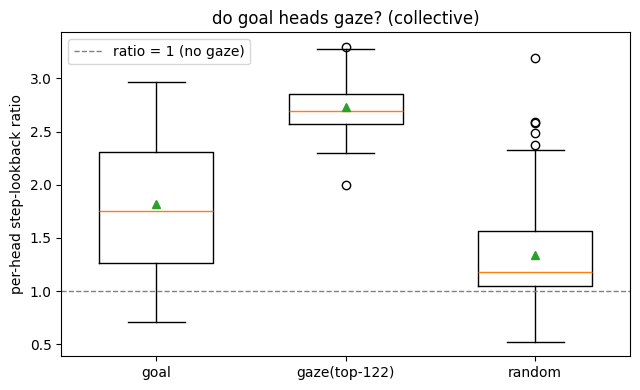

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.5, 4))
data = [set_vals(hs) for hs in HEAD_SETS.values()]
bp = ax.boxplot(data, labels=list(HEAD_SETS), showmeans=True, widths=0.6)
ax.axhline(1.0, ls="--", c="grey", lw=1, label="ratio = 1 (no gaze)")
ax.set_ylabel("per-head step-lookback ratio"); ax.set_title("do goal heads gaze? (collective)")
ax.legend(); plt.tight_layout()
FIG = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "dissociation", MODEL_NAME.split("/")[-1], "goalhead_gaze.png")
os.makedirs(os.path.dirname(FIG), exist_ok=True); plt.savefig(FIG, dpi=110, bbox_inches="tight")
print("saved", FIG); plt.show()

### 1c. goal ↔ gaze head overlap

goal=122 gaze=122 overlap=18 Jaccard=0.080


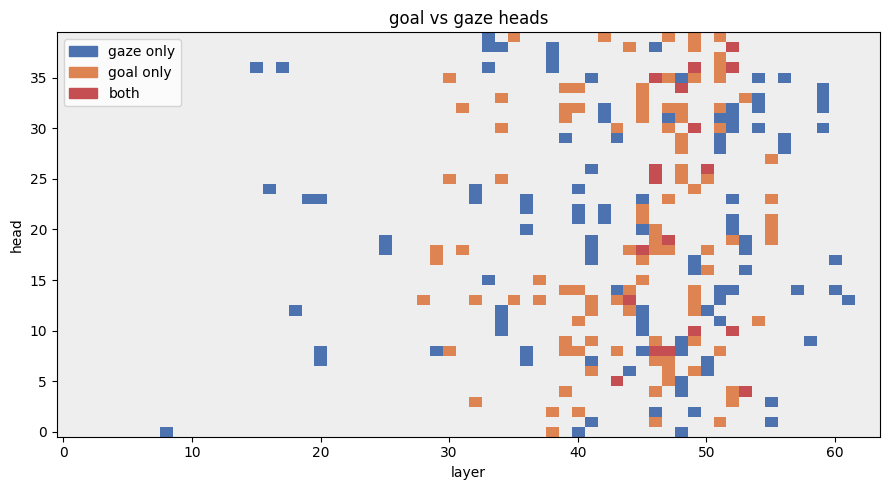

In [8]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
gset, xset = set(goal_heads), set(gaze_heads)
grid = np.zeros((N_LAYER, N_HEADS))
for l, h in xset: grid[l, h] = 1
for l, h in gset: grid[l, h] = 2 if (l, h) in xset else 3
inter = gset & xset
print(f"goal={len(gset)} gaze={len(xset)} overlap={len(inter)} Jaccard={len(inter)/len(gset|xset):.3f}")
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(grid.T, aspect="auto", cmap=ListedColormap(["#eee", "#4c72b0", "#c44e52", "#dd8452"]),
          vmin=0, vmax=3, origin="lower")
ax.set_xlabel("layer"); ax.set_ylabel("head"); ax.set_title("goal vs gaze heads")
ax.legend(handles=[mpatches.Patch(color=c, label=l) for c, l in
                   [("#4c72b0","gaze only"),("#dd8452","goal only"),("#c44e52","both")]], loc="upper left")
plt.tight_layout(); plt.show()

## 2. Do decision/impulse heads causally steer goal-head gaze?

Transplant the **move-on impulse** (decision heads, `sl→ml` mean at the pivot) into a *staying* (`ml`)
prompt and read the **goal heads'** attention. Hypothesis: the impulse pushes the goal-head gaze from
the current condition to the **next** one.

In [9]:
# ── decision / impulse heads (completion mask, tag lam10.0) — loader copied from __sanity_check ──
COMPLETION_MASK_ROOT = os.path.join(cache_root(MODEL_NAME, VERSION), "completion_mask")
COMPLETION_MASK_TAG  = "lam10.0"
SEL_THRESHOLD        = 0.8

def _list_masks():
    return sorted([(t, os.path.join(COMPLETION_MASK_ROOT, t), os.path.getmtime(os.path.join(COMPLETION_MASK_ROOT, t)))
                   for t in os.listdir(COMPLETION_MASK_ROOT)
                   if os.path.isdir(os.path.join(COMPLETION_MASK_ROOT, t))], key=lambda x: x[2], reverse=True)
_m = [it for it in _list_masks() if COMPLETION_MASK_TAG in it[0]]
assert _m, f"no completion_mask under {COMPLETION_MASK_ROOT} with tag {COMPLETION_MASK_TAG!r}"
DCK = torch.load(os.path.join(_m[0][1], "mask.pt"), map_location="cpu", weights_only=False)
dec_layers = [int(x) for x in DCK["layers"]]
dmv = DCK["mask_values"].numpy()
decision_heads = [(dec_layers[li], int(h)) for li, h in np.argwhere(dmv > SEL_THRESHOLD)]
PATCH_POS = int(DCK["patch_tokens"][0]) if len(DCK.get("patch_tokens", [-2])) == 1 else -2
print(f"decision heads: {len(decision_heads)} (thr {SEL_THRESHOLD}) · layers {min(dec_layers)}-{max(dec_layers)} · PATCH_POS={PATCH_POS}")

# binary HeadMask over the decision-mask layers (1.0 at decision heads) for the transplant
dec_mask = HeadMask(len(dec_layers), N_HEADS)
with torch.no_grad():
    dec_mask.values.zero_()
    for (l, h) in decision_heads: dec_mask.values[dec_layers.index(l), h] = 1.0

decision heads: 181 (thr 0.8) · layers 0-63 · PATCH_POS=-2


In [10]:
# ── move-on (sl) mean o_proj-input signal at PATCH_POS, over N sources ──
from src.goals.completion_pairs import build_completion_pairs, LEG_STYLES
from src.goals.head_loc_attn import get_o_proj_inputs_batch

N_MEAN_SRC, MEAN_BATCH = 200, 16
src_pairs = build_completion_pairs(mt, n_pairs=N_MEAN_SRC, direction="sl->ml", same=True,
                                   patch_tokens=(PATCH_POS,), seed=1234, log=logger.info)
src_prompts = [p.source.sl_prompt for p in src_pairs]        # "moved-on" sources
acc = {l: [] for l in dec_layers}
for i in range(0, len(src_prompts), MEAN_BATCH):
    batch = src_prompts[i:i + MEAN_BATCH]
    cache = get_o_proj_inputs_batch(mt, batch, dec_layers, token_positions=[PATCH_POS])
    for l in dec_layers: acc[l].append(cache[l][:, 0, :].float().cpu())    # (b, n_embd)
mean_src = torch.stack([torch.cat(acc[l], 0).mean(0) for l in dec_layers])  # (n_dec_layers, n_embd)
print("mean move-on signal:", tuple(mean_src.shape))

2026-07-19 14:39:53 __main__ INFO       built 25/200 pairs (27 attempts)
2026-07-19 14:40:02 __main__ INFO       built 50/200 pairs (53 attempts)
2026-07-19 14:40:11 __main__ INFO       built 75/200 pairs (81 attempts)
2026-07-19 14:40:19 __main__ INFO       built 100/200 pairs (107 attempts)
2026-07-19 14:40:28 __main__ INFO       built 125/200 pairs (135 attempts)
2026-07-19 14:40:36 __main__ INFO       built 150/200 pairs (160 attempts)
2026-07-19 14:40:44 __main__ INFO       built 175/200 pairs (185 attempts)
2026-07-19 14:40:52 __main__ INFO       built 200/200 pairs (210 attempts)
2026-07-19 14:40:52 __main__ INFO     built 200 pairs from 210 attempts
mean move-on signal: (64, 5120)


goal=122  decision=181  overlap=36  Jaccard=0.135  (29.5% of goal, 19.9% of decision)


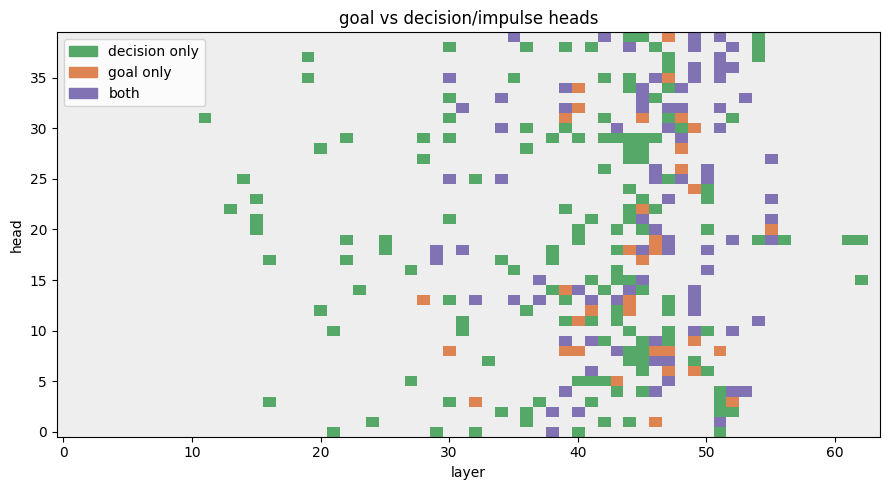

In [11]:
# ── goal ↔ decision head overlap ──
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

gset, dset = set(goal_heads), set(decision_heads)
grid = np.zeros((N_LAYER, N_HEADS))
for l, h in dset: grid[l, h] = 1
for l, h in gset: grid[l, h] = 2 if (l, h) in dset else 3
inter = gset & dset
print(f"goal={len(gset)}  decision={len(dset)}  overlap={len(inter)}  "
      f"Jaccard={len(inter)/len(gset | dset):.3f}  "
      f"({100*len(inter)/len(gset):.1f}% of goal, {100*len(inter)/len(dset):.1f}% of decision)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(grid.T, aspect="auto", origin="lower", vmin=0, vmax=3,
          cmap=ListedColormap(["#eeeeee", "#55a868", "#dd8452", "#8172b3"]))
ax.set_xlabel("layer"); ax.set_ylabel("head"); ax.set_title("goal vs decision/impulse heads")
ax.legend(handles=[mpatches.Patch(color=c, label=l) for c, l in
                   [("#55a868", "decision only"), ("#dd8452", "goal only"), ("#8172b3", "both")]],
          loc="upper left")
plt.tight_layout(); plt.show()

### 2a. Demo — goal-head attention: clean (staying) vs patched (move-on injected)

In [12]:
from src.functional import predict_next_token
from src.tokens import prepare_input
from src.goals.multiline_prompts import (
    build_example,
    replace_in_code_newline_with_tabnewline,
)
from rich.markup import escape

ds = "ml"
seed = random.Random(1123)
NAMING = "letters"
N_GEN = 64

dest_example = build_example(
    mt=mt,
    rng=seed,
    target_slot=1,
    n_conditions=4,
    mode="chat",
    style="singleline" if ds=="sl" else "multiline",
    naming=NAMING
)
dest_prompt = replace_in_code_newline_with_tabnewline(dest_example["full_prompt"]) + "   "
dest_tok = prepare_input(dest_prompt, tokenizer=mt, padding_side="left")


clean_gen = generate_with_patch(
    mt,
    inputs=dest_tok,
    n_gen_per_prompt=1,
    max_new_tokens=N_GEN,
    do_sample=False,
    remove_prefix=True,
)[0]
rich_print(
    f"[bold]clean        [/bold] [white]{escape(dest_prompt)}[/white]"
    f"[sea_green3]{escape(clean_gen)}[/sea_green3]"
)

clean_top_pred = predict_next_token(
    mt = mt,
    inputs = dest_tok,
)
clean_top_pred

clean         <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 4 digits
2. n has more than 1 ones in its binary representation
3. n has more than 6 divisors
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 4    
    b = bin(abs(n)).count("1")    
    b = b > 1    
    c = sum(1 for i in range(1, abs(n) + 1) if abs(n) % i == 0)    
    c = c > 6    
    d = n % 2 == 0    
    print(f"Condition 1

[[PredictedToken(token=' b', prob=1.0, logit=31.75, token_id=293, metadata=None),
  PredictedToken(token=' c', prob=2.905726432800293e-06, logit=19.0, token_id=272, metadata=None),
  PredictedToken(token=' d', prob=6.007030606269836e-08, logit=15.125, token_id=294, metadata=None),
  PredictedToken(token=' B', prob=3.026798367500305e-08, logit=14.4375, token_id=425, metadata=None),
  PredictedToken(token='\tb', prob=2.0838342607021332e-08, logit=14.0625, token_id=2233, metadata=None)]]

In [13]:
# ── clean dest generation  vs  head-patched dest generation ───────────────────
from src.goals.head_loc_attn import forward_with_src_replacement
from src.functional import interpret_logits
from src.goals.goalscope import headpatched_generate

def get_mask_bin(heads):
    """HeadMask (on CPU) with 1.0 for `heads`, 0.0 elsewhere. Layer index space is `layers`."""
    hm = HeadMask(mt.n_layer, mt.config.num_attention_heads)
    with torch.no_grad():
        hm.values.zero_()
        for (l, h) in heads:
            hm.values[l, h] = 1.0
    return hm

# patch the trained heads' OV write at the pivot (PATCH_POS) on the prefill only
# (n_steer_tokens=1) — matches how the mask was trained.
ALPHA = 2.0
patched_gen = headpatched_generate(
    mt,
    dest_inputs=dest_tok,
    src_o_proj_inps=mean_src,
    mask=get_mask_bin(dset),  # binarized selected heads (eval)
    layers=list(range(mt.n_layer)),
    max_new_tokens=N_GEN,
    n_steer_tokens=1,
    patch_input_positions=[PATCH_POS],
    alpha=ALPHA,
)

rich_print(
    f"[bold]patched {len(dset)}[/bold] [white]{escape(dest_prompt)}[/white]"
    f"[salmon1]{escape(patched_gen)}[/salmon1]"
)

patched_logits = forward_with_src_replacement(
    mt,
    dest_inputs=dest_tok,
    mask=get_mask_bin(dset),
    src_head_inps=mean_src,
    layers=list(range(mt.n_layer)),
    patch_positions=[PATCH_POS],
    alpha=ALPHA,
)
patched_top_pred = interpret_logits(tokenizer=mt, logits=patched_logits)
patched_top_pred

patched 181 <|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n has at least 4 digits
2. n has more than 1 ones in its binary representation
3. n has more than 6 divisors
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>    
def check_conditions(n: int):    
    a = len(str(abs(n)))    
    a = a >= 4    
    b = bin(abs(n)).count("1")    
    c = sum(1 for i in range(1, abs(n) + 1) if abs(n) % i == 0)    
    c = c > 6    
    d = n % 2 == 0    
    print(f"Condition 1: {a}, Condition 2:

[PredictedToken(token=' c', prob=0.9894347786903381, logit=25.5, token_id=272, metadata=None),
 PredictedToken(token=' d', prob=0.009700077585875988, logit=20.875, token_id=294, metadata=None),
 PredictedToken(token=' div', prob=0.0002281239430885762, logit=17.125, token_id=3429, metadata=None),
 PredictedToken(token=' i', prob=0.00015678713680244982, logit=16.75, token_id=600, metadata=None),
 PredictedToken(token=' count', prob=0.00013836417929269373, logit=16.625, token_id=1760, metadata=None)]

In [14]:
# ── §3 attention: clean vs mean-replace on the python dest ────────────────────
from src.attention import get_attention_matrices, show_interactive_attention
from src.goals.head_loc_attn import make_head_replacement_patch_interface

P_py = len(dest_tok.input_ids[0])  # dest-prompt length
pivot_abs_py = P_py + PATCH_POS  # absolute index of the patched pivot

# guard: prompt must tokenize identically as a prefix of prompt+gen so pivot_abs is correct
_clean_ids = prepare_input(dest_prompt + clean_gen, tokenizer=mt).input_ids[0]
assert _clean_ids[:P_py].tolist() == dest_tok.input_ids[0].tolist(), (
    "retokenization drift: dest_prompt is not a clean prefix of dest_prompt + clean_gen"
)

clean_attn_py = get_attention_matrices(
    input=dest_prompt + clean_gen,
    mt=mt,
    value_weighted=True,
)
show_interactive_attention(
    attn_info=clean_attn_py,
    selected_heads=sorted(gaze_heads),
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Greens",
    title=f"python | clean attention — {len(gaze_heads)} gaze heads",
    track_conditions=dest_example["spec"],
    intervened_positions=[pivot_abs_py],
    height=None,
    condition_agg="mean",
)

# head-patched attention via the SAME head-replacement transplant used for steering
_patched_ids = prepare_input(dest_prompt + patched_gen, tokenizer=mt).input_ids[0]
assert _patched_ids[:P_py].tolist() == dest_tok.input_ids[0].tolist(), (
    "retokenization drift: dest_prompt is not a clean prefix of dest_prompt + patched_gen"
)

patch_iface_py = make_head_replacement_patch_interface(
    src_head_inps=mean_src,
    mask=get_mask_bin(dset),
    layers=list(range(mt.n_layer)),
    patch_positions=[pivot_abs_py],
    alpha=ALPHA
)
patched_attn_py = get_attention_matrices(
    input=dest_prompt + patched_gen,
    mt=mt,
    value_weighted=True,
    patch_interface=patch_iface_py,
)
show_interactive_attention(
    attn_info=patched_attn_py,
    selected_heads=sorted(gaze_heads),
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Reds",
    title=f"python | mean-replace attention — {len(gaze_heads)} gaze heads | {len(dset)} patched",
    track_conditions=dest_example["spec"],
    intervened_positions=[pivot_abs_py],
    height=None,
    condition_agg="mean",
)


'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>python | mean-replace attention — 122 gaze heads | 181 patched</title>\n<style>\n #iaviz-18f47473 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-18f47473 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-18f47473 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-18f47473 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-18f47473 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-18f47473 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   m

### 2b. Flip over N=256 staying prompts — **goal vs gaze heads**, at PIVOT (-2) and LAST (-1)
For each staying (`ml`) prompt we transplant the general move-on mean into the **decision heads** at the pivot, then read gaze per condition for **both** the goal heads and the (equal-N) gaze heads off the *same* clean/patched attention. **target = next condition (cur+1)**. **hard flip** = argmax gaze == next under patch but not clean. **soft** = gaze(next) increase.

The comparison cell then asks whether the goal heads behave like the gaze heads under the impulse (same argmax condition, correlated soft-Δ, co-flipping) — i.e. whether the **goal heads are effectively functioning as gaze heads**.

In [15]:
# ── §2b: N build_example() staying prompts — decision-head move-on transplant → head-set gaze ──
# Same data recipe as the §2a demo: the dest (staying `ml`) prompt comes from build_example() alone —
# NO per-instance source pair, because the move-on impulse is the *general* mean signal `mean_src`
# (cell §2 `mean_src`, averaged over N move-on sources).  For each prompt we transplant that signal
# into the DECISION heads at the pivot whitespace and read gaze for BOTH the GOAL heads and the
# GAZE heads off the *same* clean/patched attention — so we can compare, per prompt, whether the goal
# heads shift like the dedicated gaze heads under the move-on impulse.
#   target = next condition (cur+1).  hard flip = argmax gaze == next under patch but not clean.
#   soft   = gaze(next) increase.
import random, pandas as pd
from src.goals.multiline_prompts import build_example, replace_in_code_newline_with_tabnewline
from src.attention import get_attention_matrices
from src.tokens import find_token_range
from src.goals.head_loc_attn import make_head_replacement_patch_interface

N_FLIP     = 256
N_COND     = 4
ALPHA_FLIP = ALPHA          # same transplant scale as the §2a demo
VAL_WEIGHT = True           # value-weighted attention, matching the §2a viz
FLIP_HEAD_SETS = {"goal": goal_heads, "gaze": gaze_heads}  # both read off the SAME attention
                                                           # (named apart from §1's HEAD_SETS,
                                                           #  which cell 11's boxplot still needs)

# decision-head -> residual transplant of the general move-on mean, at the pivot whitespace.
# Negative PATCH_POS lets ONE interface serve every prompt regardless of length.
flip_patch_iface = make_head_replacement_patch_interface(
    src_head_inps=mean_src, mask=dec_mask, layers=dec_layers,
    patch_positions=[PATCH_POS], alpha=ALPHA_FLIP,
)

def condition_key_idx(prompt, spec):
    # per condition -> sorted id_substr token indices in `prompt` (add_special_tokens=False)
    offs = [tuple(p) for p in mt.tokenizer(prompt, return_offsets_mapping=True,
                                           add_special_tokens=False)["offset_mapping"]]
    out = []
    for text, subs in zip(spec.spec_texts, spec.id_substrs):
        base = prompt.find(text); idx = set()
        if base != -1:
            for ss in subs:
                rel = text.find(ss)
                if rel == -1: continue
                occ = prompt.count(ss, 0, base + rel)
                try:
                    ts, te = find_token_range(prompt, ss, offset_mapping=offs, occurrence=occ)
                    idx.update(range(ts, te))
                except (ValueError, AssertionError): continue
        out.append(sorted(idx))
    return out

def headset_gaze(attn_mat, heads, cond_idx, qpos):
    # (n_cond,) mean over `heads` of mean attn from qpos to each condition's key tokens
    seq = attn_mat.shape[-1]; q = qpos % seq; out = []
    for keys in cond_idx:
        if not keys: out.append(np.nan); continue
        out.append(float(np.mean([attn_mat[l, h, q, keys].mean() for l, h in heads])))
    return np.array(out)

rng = random.Random(2025)
rows, built, attempts = [], 0, 0
while built < N_FLIP and attempts < N_FLIP * 4:
    attempts += 1
    cur = rng.randint(1, N_COND - 2); nxt = cur + 1          # staying on `cur`; target = next
    ex = build_example(mt=mt, rng=rng, target_slot=cur, n_conditions=N_COND,
                       mode="chat", style="multiline", naming="letters")
    dp = replace_in_code_newline_with_tabnewline(ex["full_prompt"]) + "   "
    sp = ex["spec"]
    cidx = condition_key_idx(dp, sp)
    if nxt >= len(cidx) or not cidx[nxt]: continue           # need the next condition visible
    A_c = np.asarray(get_attention_matrices(dp, mt, value_weighted=VAL_WEIGHT).attention_matrices)
    A_p = np.asarray(get_attention_matrices(dp, mt, value_weighted=VAL_WEIGHT,
                                            patch_interface=flip_patch_iface).attention_matrices)
    for pos in (-2, -1):
        for hname, heads in FLIP_HEAD_SETS.items():          # goal + gaze off the SAME attention
            gc = headset_gaze(A_c, heads, cidx, pos)
            gp = headset_gaze(A_p, heads, cidx, pos)
            rows.append(dict(idx=built, pos=pos, heads=hname, cur=cur, nxt=nxt,
                             clean_argmax=int(np.nanargmax(gc)), patch_argmax=int(np.nanargmax(gp)),
                             hard_flip=bool(np.nanargmax(gp) == nxt and np.nanargmax(gc) != nxt),
                             soft_delta=float(gp[nxt] - gc[nxt]),
                             next_gaze_clean=float(gc[nxt]), next_gaze_patch=float(gp[nxt])))
    built += 1
    if built % 50 == 0: logger.info(f"flip {built}/{N_FLIP}")

flip_df = pd.DataFrame(rows)
print(f"{len(flip_df)} rows = {flip_df.idx.nunique()} prompts x {flip_df.pos.nunique()} pos x "
      f"{flip_df.heads.nunique()} head-sets ({attempts} build attempts)")


2026-07-19 14:42:51 __main__ INFO     flip 50/256
2026-07-19 14:43:58 __main__ INFO     flip 100/256
2026-07-19 14:45:05 __main__ INFO     flip 150/256
2026-07-19 14:46:12 __main__ INFO     flip 200/256
2026-07-19 14:47:20 __main__ INFO     flip 250/256
1024 rows = 256 prompts x 2 pos x 2 head-sets (256 build attempts)


             gaze flip under move-on impulse — goal vs gaze heads (N=256 prompts)             
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ head-set ┃ position   ┃   n ┃ hard-flip ┃ soft Δ(next) ┃ next gaze clean ┃ next gaze patch ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ goal     │ PIVOT (-2) │ 256 │      0.91 │      +0.2534 │          0.0330 │          0.2864 │
│ goal     │ LAST (-1)  │ 256 │      0.65 │      +0.3602 │          0.0740 │          0.4342 │
│ gaze     │ PIVOT (-2) │ 256 │      0.90 │      +0.2641 │          0.0126 │          0.2767 │
│ gaze     │ LAST (-1)  │ 256 │      0.70 │      +0.3498 │          0.0484 │          0.3982 │
└──────────┴────────────┴─────┴───────────┴──────────────┴─────────────────┴─────────────────┘

saved /disk/u/arnab/Codes/Projects/goals/results/dissociation/Qwen2.5-Coder-32B-Instruct/impulse_steers_goalgaze.png


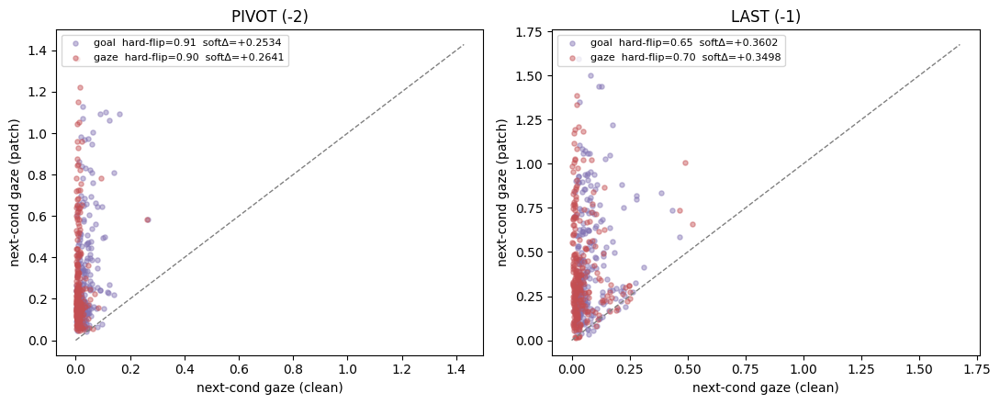

In [16]:
# ── §2b summary: per-head-set flip stats + clean-vs-patch scatter, goal vs gaze ──
HS_COLOR = {"goal": "#8172b3", "gaze": "#c44e52"}

t = Table(title=f"gaze flip under move-on impulse — goal vs gaze heads (N={flip_df.idx.nunique()} prompts)")
for c in ["head-set", "position", "n", "hard-flip", "soft Δ(next)", "next gaze clean", "next gaze patch"]:
    t.add_column(c, justify=("left" if c in ("head-set", "position") else "right"))
for hname in ("goal", "gaze"):
    for pos, lbl in [(-2, "PIVOT (-2)"), (-1, "LAST (-1)")]:
        g = flip_df[(flip_df.pos == pos) & (flip_df.heads == hname)]
        t.add_row(hname, lbl, str(len(g)), f"{g.hard_flip.mean():.2f}", f"{g.soft_delta.mean():+.4f}",
                  f"{g.next_gaze_clean.mean():.4f}", f"{g.next_gaze_patch.mean():.4f}")
rich_print(t)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pos, lbl in zip(axes, (-2, -1), ("PIVOT (-2)", "LAST (-1)")):
    lim = 0.0
    for hname in ("goal", "gaze"):
        g = flip_df[(flip_df.pos == pos) & (flip_df.heads == hname)]
        ax.scatter(g.next_gaze_clean, g.next_gaze_patch, s=14, alpha=0.45, color=HS_COLOR[hname],
                   label=f"{hname}  hard-flip={g.hard_flip.mean():.2f}  softΔ={g.soft_delta.mean():+.4f}")
        lim = max(lim, float(g.next_gaze_clean.max()), float(g.next_gaze_patch.max()))
    lim *= 1.05
    ax.plot([0, lim], [0, lim], "--", c="grey", lw=1)
    ax.set_xlabel("next-cond gaze (clean)"); ax.set_ylabel("next-cond gaze (patch)")
    ax.set_title(lbl); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
FIG2 = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "dissociation", MODEL_NAME.split("/")[-1], "impulse_steers_goalgaze.png")
plt.savefig(FIG2, dpi=110, bbox_inches="tight"); print("saved", FIG2); plt.show()


In [17]:
# ── §2b comparison: are the GOAL heads effectively functioning as GAZE heads? ──
# Both sets were read off the SAME clean/patched attention, so per prompt we can ask whether the goal
# heads (a) look at the same condition as the gaze heads (argmax agreement), and (b) shift the same way
# under the move-on impulse (paired soft-Δ correlation + co-flip rate).  soft-Δ correlation and argmax
# agreement are scale-free, so they compare the two head-sets fairly despite different attention scales.

def _pivot(pos):
    d = flip_df[flip_df.pos == pos]
    g = d[d.heads == "goal"].set_index("idx")
    z = d[d.heads == "gaze"].set_index("idx")
    return g.join(z, lsuffix="_goal", rsuffix="_gaze")

ct = Table(title="goal-vs-gaze agreement — do goal heads gaze like gaze heads?")
for c in ["position", "argmax agree (clean)", "argmax agree (patch)", "soft-Δ corr r",
          "goal hard-flip", "gaze hard-flip", "co-flip (goal | gaze)"]:
    ct.add_column(c, justify=("left" if c == "position" else "right"))
for pos, lbl in [(-2, "PIVOT (-2)"), (-1, "LAST (-1)")]:
    j = _pivot(pos)
    agree_c = float((j.clean_argmax_goal == j.clean_argmax_gaze).mean())
    agree_p = float((j.patch_argmax_goal == j.patch_argmax_gaze).mean())
    r = float(np.corrcoef(j.soft_delta_goal, j.soft_delta_gaze)[0, 1]) if len(j) > 2 else float("nan")
    gz = j[j.hard_flip_gaze]                                   # prompts where gaze heads flipped
    coflip = float(gz.hard_flip_goal.mean()) if len(gz) else float("nan")
    ct.add_row(lbl, f"{agree_c:.2f}", f"{agree_p:.2f}", f"{r:+.2f}",
               f"{j.hard_flip_goal.mean():.2f}", f"{j.hard_flip_gaze.mean():.2f}",
               f"{coflip:.2f}" if coflip == coflip else "—")
rich_print(ct)

# crude read at the pivot: high argmax agreement under patch + positive soft-Δ correlation
j = _pivot(-2)
agree_p = float((j.patch_argmax_goal == j.patch_argmax_gaze).mean())
r = float(np.corrcoef(j.soft_delta_goal, j.soft_delta_gaze)[0, 1]) if len(j) > 2 else float("nan")
verdict = ("goal heads TRACK gaze heads (function like them under the impulse)"
           if (agree_p >= 0.5 and r > 0.2)
           else "goal heads do NOT cleanly track gaze heads")
rich_print(f"[bold]PIVOT verdict:[/bold] argmax-agree(patch)={agree_p:.2f}, soft-Δ r={r:+.2f} → {verdict}")


                           goal-vs-gaze agreement — do goal heads gaze like gaze heads?                            
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃            ┃   argmax agree ┃   argmax agree ┃               ┃                ┃                ┃  co-flip (goal ┃
┃ position   ┃        (clean) ┃        (patch) ┃ soft-Δ corr r ┃ goal hard-flip ┃ gaze hard-flip ┃        | gaze) ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ PIVOT (-2) │           0.97 │           0.95 │         +0.93 │           0.91 │           0.90 │           0.97 │
│ LAST (-1)  │           0.84 │           0.97 │         +0.90 │           0.65 │           0.70 │           0.85 │
└────────────┴────────────────┴────────────────┴───────────────┴────────────────┴────────────────┴────────────────┘

PIVOT verdict: argmax-agree(patch)=0.95, soft-Δ r=+0.93 → goal heads TRACK gaze heads (function like them under the
impulse)